# The counterbalancing capacity: haircuts, monetisation capacity and held-to-maturity losses

**Question:** How much cash can the bank that failed in March 2023 raise against its securities, how fast, and how many days of survival does the unrealised loss on its held-to-maturity book take away?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 and 02 of this topic
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- compute the liquidity value of an asset class (market value, less the encumbered part, less a haircut) and say which rule gave each haircut;
- turn the liquidity values into a counterbalancing capacity (CBC) that grows day by day with a monetisation schedule;
- measure how the unrealised loss of a held-to-maturity (HTM) book removes CBC and shortens the survival period;
- read the product's tests on the haircut rules, on the HTM effect and on the revaluation of the HTM book, and the survival days that the loss costs.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Two committed documents of case C16 (real FDIC call-report aggregates of the bank that failed on 2023-03-10 up to 2022-12-31, synthetic behaviour and deposits, licence class `mirror-allowed`):

- `data/derived/C16/list-adverse.json`: the CBC classes at the carrying value of the securities (the amortised-cost basis), the conventions of the haircuts and of the monetisation schedule, and the survival period.
- `data/derived/C16/htm-losses.json`: the same ladder with the securities book at fair value, the effect of the loss on the CBC and the committed tests.

The central bank haircuts are one minus the margins of the Federal Reserve discount window in force on 2023-03-10 (Federal Reserve discount window, 2022-2023), taken by class from the document. Amounts are in USD thousands.

In [2]:
# Load the two committed documents (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
folder = ROOT / "data" / "derived" / "C16"
adverse = json.loads((folder / "list-adverse.json").read_text(encoding="utf-8"))
htm_doc = json.loads((folder / "htm-losses.json").read_text(encoding="utf-8"))
out, htm_out = adverse["outputs"], htm_doc["outputs"]

for name, doc in (("list-adverse", adverse), ("htm-losses", htm_doc)):
    baked = doc["provenance"]["riskvalidation_version"]
    print(name, "| baked by riskvalidation", baked, "| installed", rv.__version__)
framework = out["cbc"]["haircut_framework"]
print("valuation date:", out["valuation_date"])
print("haircut framework in force from", framework["effective_from"], "to", framework["effective_to"])

list-adverse | baked by riskvalidation 1.0.1 | installed 1.0.1
htm-losses | baked by riskvalidation 1.0.1 | installed 1.0.1
valuation date: 2022-12-31
haircut framework in force from 2022-03-14 to 2023-03-12


## Method

### Step 1: the liquidity value of an asset

The liquidity value of an asset class is its market value less a haircut, and only the unencumbered part counts (ECB, 2019, methodological note, paragraphs 63 and 74). With market value $M$, encumbered part $E$ and haircut $h$:

$$\mathrm{LV} = (M - E)\,(1 - h)$$

The call report gives the securities by type at their carrying value and the pledged amount (`SCPLEDGE`); the document spreads the pledged amount pro rata across the types, a stated assumption. The next cell takes the six classes of the document, calls `liquidity_value` for each and prints the table.

In [3]:
# The liquidity value of each class from its value used, encumbered part and haircut
from riskvalidation.liquidity.cbc import liquidity_value

classes = out["cbc"]["classes"]
values = [liquidity_value(c["value_used"], c["haircut"]["value"], c["encumbered"]) for c in classes]

columns = f"{'class':18s}{'value used':>12s}{'encumbered':>12s}{'haircut':>9s}{'liquidity value':>17s}"
print(columns, "  (USD billions)")
for c, lv in zip(classes, values):
    left = f"{c['class_id']:18s}{c['value_used'] / 1e6:12.3f}{c['encumbered'] / 1e6:12.3f}"
    print(left + f"{c['haircut']['value']:9.2f}{lv / 1e6:17.3f}")
total = sum(values)
print("total liquidity value (USD billions):", round(total / 1e6, 4))
print("pledged share of the securities:", round(out["cbc"]["pledged"]["share_of_securities"], 4))

class               value used  encumbered  haircut  liquidity value   (USD billions)
cash-and-balances       12.511       0.000     0.00           12.511
treasury                16.043       7.571     0.02            8.302
mortgage-backed         91.460      43.164     0.04           46.364
other-agency             0.587       0.277     0.03            0.301
municipal                7.417       3.500     0.05            3.721
other-debt               1.796       0.848     0.50            0.474
total liquidity value (USD billions): 71.6726
pledged share of the securities: 0.4719


The next cell draws where the value of each class goes: counted as liquidity value, removed by the haircut, or encumbered.

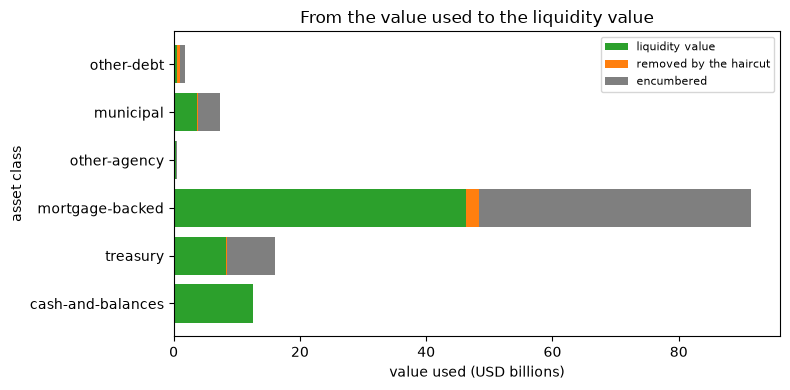

In [4]:
# Draw where the value of each class goes: liquidity value, cut by the haircut, or encumbered
names = [c["class_id"] for c in classes]
encumbered = np.array([c["encumbered"] for c in classes]) / 1e6
counted = np.array(values) / 1e6
cut = np.array([c["value_used"] for c in classes]) / 1e6 - encumbered - counted
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(names, counted, color="tab:green", label="liquidity value")
ax.barh(names, cut, left=counted, color="tab:orange", label="removed by the haircut")
ax.barh(names, encumbered, left=counted + cut, color="tab:gray", label="encumbered")
ax.set_xlabel("value used (USD billions)")
ax.set_ylabel("asset class")
ax.set_title("From the value used to the liquidity value")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The mortgage-backed securities dominate the stack: of 91.460 billion USD held, 43.164 are encumbered and the rest, after a 4% haircut, leaves 46.364 of liquidity value. The Treasuries show the same pattern at a smaller scale (16.043 held, 7.571 pledged, 8.302 counted). The grey bars are the main loss of capacity: the pledged securities are 0.4719 of the securities book, while the orange slices, the haircuts, are barely visible because the discount window margins are generous, between 2% and 5%. The total is 71.6726 billion. The figure does not say how fast that stock turns into cash, which is the question of step 3.

### Step 2: which rule gave the haircut

The note fixes an order for the haircut of an asset (paragraph 74): cash at nominal value (haircut 0); a central-bank-eligible asset takes the central bank's haircut; if that cannot be determined, the LCR haircut when the asset is high-quality liquid (HQLA) and 50% otherwise; a marketable asset that is not eligible takes the table of equities by rating (20%, 35%, 50%) or 30% if it is HQLA and 50% if not. `haircut_rule` returns the haircut and the label of the rule that gave it. The next cell applies it to the classes of the document, with the central bank haircut of each class (one minus the Federal Reserve margin) when the framework gives one.

In [5]:
# The haircut rule of each class: the central bank haircut when the Federal Reserve gives a margin, else the fallback
from riskvalidation.liquidity.cbc import haircut_rule

mapping = {row["class_id"]: row for row in out["conventions"]["cbc_securities_mapping"]["rows"]}
print(f"{'class':18s}{'margin':>9s}{'maturity bucket':>17s}{'haircut':>9s}  rule given by the engine")
for c in classes:
    row = mapping[c["class_id"]]
    margin = row["margin"]
    central = None if margin is None else 1.0 - margin
    if c["class_id"] == "cash-and-balances":
        haircut, rule = haircut_rule("cash")
    else:
        haircut, rule = haircut_rule("non-equity", central_bank_eligible=True, central_bank_haircut=central)
    margin_text = "-" if margin is None else f"{margin:.2f}"
    bucket = "-" if row["duration_bucket"] == "none" else row["duration_bucket"]
    print(f"{c['class_id']:18s}{margin_text:>9s}{bucket:>17s}{haircut:9.2f}  {rule}")

class                margin  maturity bucket  haircut  rule given by the engine
cash-and-balances         -                -     0.00  nominal-value
treasury               0.98             >3-5     0.02  central-bank-framework
mortgage-backed        0.96            >5-10     0.04  central-bank-framework
other-agency           0.97             >3-5     0.03  central-bank-framework
municipal              0.95            >5-10     0.05  central-bank-framework
other-debt                -                -     0.50  fifty-percent-fallback


The product also commits a test that runs the whole order of the note on nine constructed cases (the three equity bands, the HQLA and the fallback cases, the central bank cases, cash). The next cell calls it and prints the rule that each case receives.

In [6]:
# The haircut-rule test on nine constructed cases: the order of the note, rule by rule
from riskvalidation.validation.liquidity import cbc_haircut_rules

rules = cbc_haircut_rules()
for case in rules.extras["cases"]:
    print(f"{case['kind']:12s} haircut and rule: {case['got']}")
print("cases:", rules.n, "| largest difference to the expected:", rules.statistic, "| light:", rules.light.value)

equity       haircut and rule: [0.2, 'ecb-equity-table']
equity       haircut and rule: [0.35, 'ecb-equity-table']
equity       haircut and rule: [0.5, 'ecb-equity-table']
non-equity   haircut and rule: [0.3, 'ecb-non-equity-hqla']
non-equity   haircut and rule: [0.5, 'fifty-percent-fallback']
non-equity   haircut and rule: [0.04, 'central-bank-framework']
non-equity   haircut and rule: [0.15, 'lcr-haircut-hqla']
non-equity   haircut and rule: [0.5, 'fifty-percent-fallback']
cash         haircut and rule: [0.0, 'nominal-value']
cases: 9 | largest difference to the expected: 0.0 | light: green


### Step 3: from liquidity value to a CBC that grows by day

Assets are not cash on day 1. A monetisation schedule gives the cumulative share of the liquidity value that can be turned into cash by each day, so the CBC of day $d$ is:

$$\mathrm{CBC}(d) = \sum_{c} \mathrm{LV}_c \; \sigma(d)$$

where $\sigma(d)$ is the share of the last point of the schedule with day $\le d$ (zero before the first point). The dossier names the capacity per day but gives no value, so the schedule of the document (50% on day 1, 80% on day 2, 100% on day 3) is a stated convention, with an immediate and a slow bound. `cbc_stack` returns the CBC by class; the next cell prints it for day 1 and shows the three schedules at days 1, 5 and 10.

In [7]:
# The CBC stack by class under the schedule of the document, and the immediate and slow bounds
from riskvalidation.liquidity.cbc import cbc_stack, monetisation_capacity

schedule = out["conventions"]["monetisation_schedule"]
points = [(p["day"], p["cumulative_share"]) for p in schedule["points"]]
inputs = {c["class_id"]: (c["value_used"], c["encumbered"], c["haircut"]["value"]) for c in classes}
stack = cbc_stack(inputs, points, 125)

print("schedule (day, cumulative share):", points)
print("CBC of day 1 by class (USD billions):", {k: round(float(v[0]) / 1e6, 3) for k, v in stack.items()})
bands = schedule["sensitivity_band"]
bounds = {band["id"]: [(p["day"], p["cumulative_share"]) for p in band["points"]] for band in bands}
bounds["document"] = points
paths = {name: monetisation_capacity(total, pts, 125) for name, pts in bounds.items()}
for name, path in paths.items():
    at_days = [round(float(path[d - 1]) / 1e6, 2) for d in (1, 5, 10)]
    print(f"{name:10s} CBC at days 1, 5 and 10 (USD billions):", at_days)

schedule (day, cumulative share): [(1, 0.5), (2, 0.8), (3, 1.0)]
CBC of day 1 by class (USD billions): {'cash-and-balances': 6.255, 'treasury': 4.151, 'mortgage-backed': 23.182, 'other-agency': 0.15, 'municipal': 1.86, 'other-debt': 0.237}
immediate  CBC at days 1, 5 and 10 (USD billions): [71.67, 71.67, 71.67]
slow       CBC at days 1, 5 and 10 (USD billions): [17.92, 43.0, 71.67]
document   CBC at days 1, 5 and 10 (USD billions): [35.84, 71.67, 71.67]


The next cell draws the CBC over the first ten days under the three schedules.

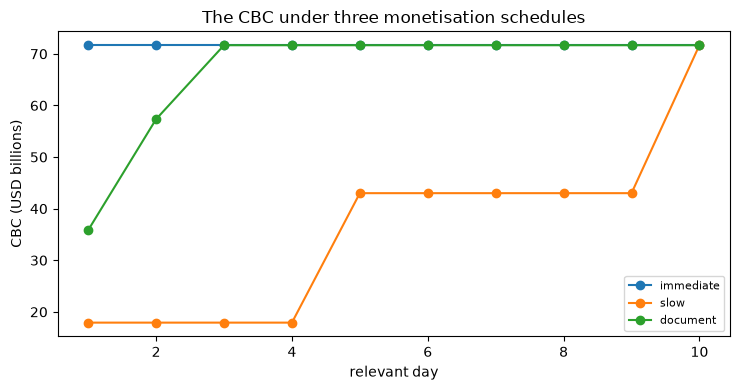

In [8]:
# Draw the CBC over the first ten days under the three monetisation schedules
fig, ax = plt.subplots(figsize=(7.5, 4))
for name, path in paths.items():
    ax.plot(range(1, 11), path[:10] / 1e6, marker="o", label=name)
ax.set_xlabel("relevant day")
ax.set_ylabel("CBC (USD billions)")
ax.set_title("The CBC under three monetisation schedules")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The three lines reach the same ceiling, 71.67 billion USD, on different days. The immediate bound has all of it from day 1, the schedule of the document has 35.84 billion on day 1 and the full amount by day 5, and the slow bound crawls through 17.92 on day 1 and 43.00 on day 5 to arrive on day 10. So the schedule moves the first days of the ladder and never the total, which is why it matters for a run that bites in the first week. It is a stated convention: the research dossier names the capacity per day and gives no value. The figure does not show the loss on the securities, which comes next.

### Step 4: the unrealised loss of a held-to-maturity book

A held-to-maturity book is carried at amortised cost, so the call report hides its loss from the liquidity picture; but a bank that has to sell or pledge those securities in a stress receives their fair value, not their carrying value. Unrealised losses therefore reduce the effective CBC and can trigger runs (Jiang et al., 2024; ECB, 2019). For a class with carrying value $K$, fair value $V$, encumbered part $E$ and haircut $h$:

$$\Delta = V - K, \qquad \mathrm{CBC}_{\text{with}} = (V - E)(1 - h), \qquad \mathrm{removed} = (K - E)(1 - h) - (V - E)(1 - h)$$

The call report gives the reported fair value of the held-to-maturity book (`SCHF`) and of the available-for-sale book; it gives no loss by type. The document applies the reported loss to the whole securities book pro rata by type, a stated assumption, never a reported loss by type. The encumbered amount is the same on both bases. The next cell runs `cbc_with_htm_loss` class by class.

In [9]:
# The CBC with and without the loss, class by class, from the engine; cash has no loss
from riskvalidation.liquidity.cbc import cbc_with_htm_loss

htm = htm_out["htm"]
carrying = {c["class_id"]: c for c in classes}
without = carrying["cash-and-balances"]["liquidity_value"]
with_loss = without
by_class = {}
columns = f"{'class':18s}{'unrealised loss':>17s}{'CBC without':>13s}{'CBC with':>10s}{'removed':>9s}"
print(columns, "  (USD billions)")
for c in htm_out["cbc"]["classes"]:
    if c["class_id"] == "cash-and-balances":
        continue
    base = carrying[c["class_id"]]
    result = cbc_with_htm_loss(base["carrying_value"], c["fair_value"], c["encumbered"], c["haircut"]["value"])
    without += result.cbc_without_loss
    with_loss += result.cbc_with_loss
    by_class[c["class_id"]] = (result.cbc_without_loss, result.cbc_with_loss)
    left = f"{c['class_id']:18s}{result.unrealised_loss / 1e6:17.3f}{result.cbc_without_loss / 1e6:13.3f}"
    print(left + f"{result.cbc_with_loss / 1e6:10.3f}{result.cbc_removed / 1e6:9.3f}")
print("total CBC without and with the loss (USD billions):", round(without / 1e6, 4), round(with_loss / 1e6, 4))
print("removed (USD billions):", round((without - with_loss) / 1e6, 4))

class               unrealised loss  CBC without  CBC with  removed   (USD billions)
treasury                     -2.073        8.302     6.270    2.032
mortgage-backed             -11.819       46.364    35.017   11.347
other-agency                 -0.076        0.301     0.227    0.074
municipal                    -0.958        3.721     2.810    0.911
other-debt                   -0.232        0.474     0.358    0.116
total CBC without and with the loss (USD billions): 71.6726 57.1941
removed (USD billions): 14.4785


The next cell draws the CBC of each class on the carrying value and with the unrealised loss.

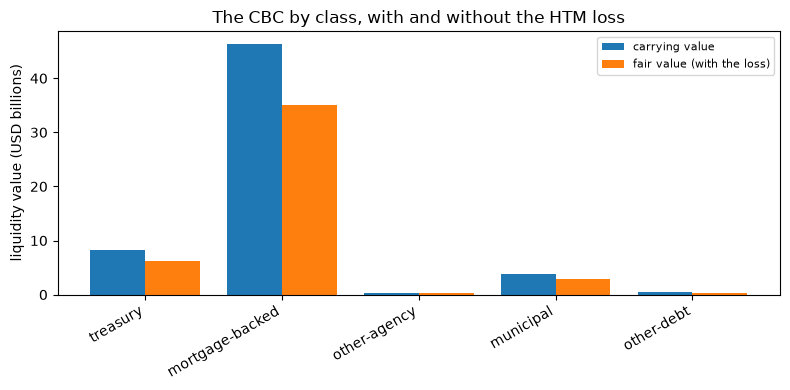

In [10]:
# Draw the CBC of each class on the carrying value and with the unrealised loss of the HTM book
names = list(by_class)
position = np.arange(len(names))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(position - 0.2, [by_class[k][0] / 1e6 for k in names], width=0.4, label="carrying value")
ax.bar(position + 0.2, [by_class[k][1] / 1e6 for k in names], width=0.4, label="fair value (with the loss)")
ax.set_xticks(position)
ax.set_xticklabels(names, rotation=30, ha="right")
ax.set_ylabel("liquidity value (USD billions)")
ax.set_title("The CBC by class, with and without the HTM loss")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The mortgage-backed securities carry most of the CBC and most of the loss: their liquidity value falls from 46.364 to 35.017 billion USD, 11.347 of the 14.4785 billion that the loss removes in total (from 71.6726 to 57.1941). The Treasuries lose a quarter of theirs, 2.032 of 8.302 billion. The loss is spread pro rata by type because the call report gives none by type, so the split between bars is an assumption of the product and only the total is a reported figure. The figure does not show the effect on the survival period; that is the next step.

### Step 5: the effect on the survival period

The test `liq.htm_loss_effect` takes the CBC and the survival period without and with the loss and checks the direction of the effect: the loss should not raise the CBC and should not lengthen the survival period. Its statistic is the CBC removed and its metric the share of the CBC removed. A green light says the effect has the expected sign, not that the loss is small. The survival periods are those of the two documents (LiST Adverse on the carrying value and on the fair value). The next cell calls the test.

In [11]:
# The HTM loss effect test: CBC and survival period without and with the loss
from riskvalidation.validation.liquidity import htm_loss_effect

survival_without = out["path"]["survival"]["day"]
survival_with = htm_out["path"]["survival"]["day"]
effect = htm_loss_effect(without, with_loss, survival_without, survival_with)

print("survival period without and with the loss (days):", survival_without, survival_with)
print("CBC removed (USD billions):", round(effect.statistic / 1e6, 4))
print("share of the CBC removed:", round(effect.metric, 6), "| light:", effect.light.value)

survival period without and with the loss (days): 62 44
CBC removed (USD billions): 14.4785
share of the CBC removed: 0.202009 | light: green


The loss is also a dial. `htm_loss_grid` scales the reported loss by a multiple (0 removes it, 1 is the reported loss) and the document runs the ladder at each multiple. The next cell recomputes the losses of the grid from the reported one and prints them with the CBC and the survival period that the product's ladder gives at each multiple (those two columns are baked by the pipeline; re-running the ladder is the work of notebook 04).

In [12]:
# The HTM loss grid: the engine's losses for each multiple, with the ladder's CBC and survival period at each
from riskvalidation.liquidity.scenarios import htm_loss_grid

grid = out["sensitivities"]["htm_loss"]
multiples = [row["multiple"] for row in grid]
losses = htm_loss_grid(htm["reported"]["htm_unrealised"], multiples)

print(f"{'multiple':>9s}{'loss (USD billions)':>21s}{'CBC':>9s}{'survival day':>14s}")
for row, loss in zip(grid, losses):
    print(f"{row['multiple']:9.1f}{loss / 1e6:21.3f}{row['cbc'] / 1e6:9.2f}{row['survival']['day']:14d}")

 multiple  loss (USD billions)      CBC  survival day
      0.0               -0.000    71.67            62
      0.5               -7.580    64.43            53
      1.0              -15.159    57.19            44
      1.5              -22.738    49.95            36
      2.0              -30.318    42.72            28


The next cell draws the survival period against the multiple of the reported loss.

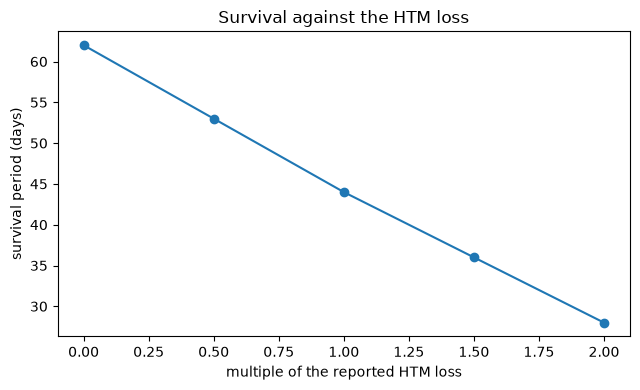

In [13]:
# Draw the survival period against the multiple of the reported HTM loss
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(multiples, [row["survival"]["day"] for row in grid], marker="o")
ax.set_xlabel("multiple of the reported HTM loss")
ax.set_ylabel("survival period (days)")
ax.set_title("Survival against the HTM loss")
fig.tight_layout()
plt.show()

The line falls steadily: 62 days with no loss, 53 with half of the reported loss, 44 with all of it, 36 at one and a half times and 28 at twice. Each half step costs 8 or 9 days, so the effect is close to linear in the range tried, and the reported loss alone takes 18 days off the bank's life. The product's ladder gives the CBC and the survival day in this figure, and the unrealised loss is what the engine takes from the CBC; the figure does not say how the bank would have funded itself against the securities at par, which is the counterfactual of step 6.

### Step 6: does the engine reproduce the reported fair value?

The product does not take the reported fair value on trust. The test `liq.htm_revaluation_vs_reported` revalues the HTM book from its maturity profile under the Treasury par curve (a par bond per maturity band, through the engine's `irrbb` curves) and compares it with the reported fair value $V_r$, as a share of the reported unrealised loss:

$$\text{statistic} = \frac{|V_{\text{model}} - V_r|}{|V_r - K|}$$

The light is an internal gate of the product (green up to 0.05, amber up to 0.15, red above), not a regulatory threshold. The revaluation is committed in the document; the next cell calls the test with those inputs and prints the Bank Term Funding Program counterfactual that the document also carries (par valuation announced on 2023-03-12, after the run).

In [14]:
# The revaluation test with the revaluation of the document, and the par counterfactual
from riskvalidation.validation.liquidity import htm_revaluation_vs_reported

revaluation = htm["revaluation"]
reported = htm["reported"]
check = htm_revaluation_vs_reported(
    revaluation["model_fair_value"], reported["htm_fair_value"], reported["htm_amortised_cost"]
)

print("reported fair value (USD billions):", round(reported["htm_fair_value"] / 1e6, 3))
print("revalued by the model (USD billions):", round(revaluation["model_fair_value"] / 1e6, 3))
print("statistic:", round(check.statistic, 6), "| difference (USD billions):", round(check.metric / 1e6, 3))
print("light:", check.light.value)
par = htm["btfp_par"]
print("counterfactual at par: CBC (USD billions):", round(par["cbc_at_par"] / 1e6, 3))
print("uplift of the CBC at par (USD billions):", round(par["uplift"] / 1e6, 3))
print("par valuation announced on", par["announced"])

reported fair value (USD billions): 76.168
revalued by the model (USD billions): 71.9
statistic: 0.281548 | difference (USD billions): -4.268
light: red
counterfactual at par: CBC (USD billions): 73.783
uplift of the CBC at par (USD billions): 2.111
par valuation announced on 2023-03-12


## Results

**Answer:** Against its securities and cash the bank can raise at most 71.6726 billion USD: 35.84 billion on day 1 and the full 71.67 billion by day 5 under the schedule of the document, after 43.164 of its 91.460 billion of mortgage-backed securities are encumbered. The unrealised loss of the held-to-maturity book removes 14.4785 billion of that capacity, 0.202009 of it, and shortens the survival period from 62 to 44 days.

- **Liquidity values.** The six classes give a total liquidity value of 71.6726 billion USD. The mortgage-backed securities hold 46.364 billion of it, after 43.164 billion of their 91.460 billion are encumbered: the pledged securities are 0.4719 of the securities book and leave the CBC.
- **Haircut rules.** Four classes take the Federal Reserve margin (haircuts from 0.02 to 0.05), cash is at nominal value, and the class of other debt, which has no margin, falls back to 50%. The haircut test on the nine constructed cases ends with a largest difference of 0.0 to its expected values.
- **The CBC by day.** Under the schedule of the document the CBC is 35.84 billion on day 1 and the full 71.67 billion from day 5; under the immediate bound it is 71.67 from day 1, and under the slow bound it is 17.92, 43.00 and 71.67 on days 1, 5 and 10. The schedule moves the first days, not the total, and it is a convention: the dossier names the capacity per day and gives no value.
- **The HTM loss.** Applying the reported held-to-maturity loss (15.159 billion) pro rata removes 14.4785 billion of CBC, 0.202009 of it (from 71.6726 to 57.1941), 11.347 billion of that in mortgage-backed securities. The survival period falls from 62 to 44 days, and each half step of the loss costs 8 or 9 days. The test is green because the effect has the expected sign.
- **The revaluation.** The revaluation of the HTM book, 71.900 billion, is 4.268 billion below the reported fair value of 76.168 billion: 0.281548 of the reported unrealised loss, red under the gates of 0.05 and 0.15. The counterfactual at par (the valuation announced on 2023-03-12, after the run) would have lifted the CBC by 2.111 billion to 73.783 billion. The red light says the model and the reported figure disagree, so the loss used above is itself uncertain; the model values a par bond per maturity band, a simplification, so it is not a finding on the bank's accounts.

What this notebook does not show: the outflow side of the NLP (notebooks 02 and 04) or the LCR view of the same assets (notebook 05). The HTM loss is spread pro rata by type because the call report gives none by type; the survival periods are properties of synthetic behaviour.

## Summary

- The liquidity value of an asset is $(M-E)(1-h)$; the rule that gave the haircut is part of the result, and the engine returns its label.
- The CBC is not the sum of the liquidity values on day 1: it follows a monetisation schedule, a stated convention with an immediate and a slow bound.
- The unrealised loss of a held-to-maturity book removes CBC and survival days, and the effect grows with the loss.
- The engine's own revaluation of the HTM book does not reproduce the reported fair value within the product's gate: the reported figure is an input to be tested, not a given.

**What to try next.** Change the multiple of the grid to 3 and look at the survival period; then continue with notebook 04, where the outflow side is composed into scenarios.

## References

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06), paragraphs 63, 73 and 74 and Table 2.1. https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- Federal Reserve discount window, securities margins in force from 2022-03-14 to 2023-03-12. https://www.frbdiscountwindow.org/generalpages/historical_margins/2022/03142022_03122023_securities_table
- Jiang, E. X., Matvos, G., Piskorski, T. and Seru, A. (2024), Monetary tightening and U.S. bank fragility in 2023: mark-to-market losses and uninsured depositor runs?, Journal of Financial Economics 159. https://doi.org/10.1016/j.jfineco.2024.103899